# Data Mining Lab Assignment
## Book Recommender System using a Medallion Data Lake

**Dataset:** Book-Crossing — Users, Books, Book-Ratings  
**Pipeline:** Bronze → Silver → Gold → Item-Based Collaborative Filtering

This notebook implements the complete assignment. Run the cells from top to bottom in Google Colab. The notebook downloads the original dataset, creates the three data-lake layers, performs EDA and cleaning, builds model-ready Gold data, and demonstrates recommendations for at least three users.

**Reproducibility note:** The notebook does not hardcode EDA results or demo user IDs. Those are calculated from the downloaded data after the pipeline runs.

## 1. Install dependencies

We use Pandas for tabular processing, PyArrow for Parquet, SciPy for sparse matrices, and scikit-learn for cosine-neighbour search.

In [8]:
%pip -q install pandas numpy scipy scikit-learn pyarrow matplotlib seaborn

## 2. Imports and configuration

In [9]:
import os
import zipfile
import csv
import warnings
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.sparse import csr_matrix, save_npz, load_npz
from sklearn.neighbors import NearestNeighbors
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
MIN_RATINGS = 10
HIGH_RATING = 7

DATASET_URL = (
    "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
)
ZIP_PATH = "book-crossings.zip"
RAW_DIR = "raw_data"

for folder in ["bronze", "silver", "gold"]:
    os.makedirs(folder, exist_ok=True)

print("Environment ready.")
print("Working directory:", os.getcwd())

Environment ready.
Working directory: /content


## 3. Download and inspect the source files

The source files are semicolon-delimited and use a Latin-1 encoding. ISBN values are read as strings so leading zeroes and non-numeric characters are preserved. The original ZIP is retained as the source snapshot.

In [10]:
import os
import zipfile
import subprocess

ZIP_PATH = "book-crossings.zip"
RAW_DIR = "raw_data"

# Remove any incomplete download
if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)

# Download using wget instead of Python urllib
url = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"

result = subprocess.run([
    "wget",
    "--user-agent=Mozilla/5.0",
    "-O", ZIP_PATH,
    url
])

if result.returncode != 0:
    raise RuntimeError("Dataset download failed. Try the fallback below.")

# Verify the downloaded file
if not zipfile.is_zipfile(ZIP_PATH):
    raise RuntimeError("Downloaded file is not a valid ZIP archive.")

# Extract dataset
os.makedirs(RAW_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(RAW_DIR)

print("Dataset downloaded and extracted successfully!")
print(os.listdir(RAW_DIR))

Dataset downloaded and extracted successfully!
['BX-Books.csv', 'BX-Users.csv', 'BX-Book-Ratings.csv']


In [11]:
import csv

users_raw = pd.read_csv(
    users_csv,
    sep=";",
    encoding="latin-1",
    quotechar='"',
    on_bad_lines="error"
)

books_raw = pd.read_csv(
    books_csv,
    sep=";",
    encoding="latin-1",
    quotechar='"',
    engine="python",
    on_bad_lines="warn"
)

ratings_raw = pd.read_csv(
    ratings_csv,
    sep=";",
    encoding="latin-1",
    quotechar='"',
    on_bad_lines="error"
)

print("All datasets loaded!")
print("Users:", users_raw.shape)
print("Books:", books_raw.shape)
print("Ratings:", ratings_raw.shape)

/tmp/ipykernel_2593/784763775.py:11: ParserWarning: Skipping line 815: ';' expected after '"'

  books_raw = pd.read_csv(
/tmp/ipykernel_2593/784763775.py:11: ParserWarning: Skipping line 1679: ';' expected after '"'

  books_raw = pd.read_csv(
/tmp/ipykernel_2593/784763775.py:11: ParserWarning: Skipping line 2531: ';' expected after '"'

  books_raw = pd.read_csv(
/tmp/ipykernel_2593/784763775.py:11: ParserWarning: Skipping line 2640: ';' expected after '"'

  books_raw = pd.read_csv(
/tmp/ipykernel_2593/784763775.py:11: ParserWarning: Skipping line 3236: ';' expected after '"'

  books_raw = pd.read_csv(
/tmp/ipykernel_2593/784763775.py:11: ParserWarning: Skipping line 3256: ';' expected after '"'

  books_raw = pd.read_csv(
/tmp/ipykernel_2593/784763775.py:11: ParserWarning: Skipping line 4906: ';' expected after '"'

  books_raw = pd.read_csv(
/tmp/ipykernel_2593/784763775.py:11: ParserWarning: Skipping line 6452: ';' expected after '"'

  books_raw = pd.read_csv(
/tmp/ipykernel_25

All datasets loaded!
Users: (278858, 3)
Books: (270491, 8)
Ratings: (1149780, 3)


## 4. Bronze layer — raw ingestion

Bronze contains the parsed source tables without analytical cleaning. The only added field is `ingestion_timestamp`, as required. The original ZIP and extracted CSV files are also retained in the Colab working directory as source files.

In [12]:
ingestion_timestamp = datetime.now(timezone.utc)

users_bronze = users_raw.copy()
books_bronze = books_raw.copy()
ratings_bronze = ratings_raw.copy()

for frame in (users_bronze, books_bronze, ratings_bronze):
    frame["ingestion_timestamp"] = ingestion_timestamp

users_bronze.to_parquet("bronze/users.parquet", index=False)
books_bronze.to_parquet("bronze/books.parquet", index=False)
ratings_bronze.to_parquet("bronze/ratings.parquet", index=False)

print("Bronze Parquet files written.")

Bronze Parquet files written.


## 5. Explore the Bronze data (EDA)

The following cells calculate the required shapes, data types, missing-value counts, rating distribution, age/publication-year distributions, ratings-per-user/book and user-book matrix sparsity. Use the actual outputs when describing findings in your lab explanation.

In [13]:
# Read Bronze back from Parquet, as required by the assignment.
users_bronze = pd.read_parquet("bronze/users.parquet")
books_bronze = pd.read_parquet("bronze/books.parquet")
ratings_bronze = pd.read_parquet("bronze/ratings.parquet")

def inspect_table(frame, table_name):
    print("\n" + "=" * 70)
    print(table_name)
    print("=" * 70)
    print("Shape:", frame.shape)
    print("\nData types:")
    display(frame.dtypes.to_frame("dtype"))
    print("\nMissing values:")
    display(frame.isna().sum().to_frame("missing_count"))

inspect_table(users_bronze, "USERS — BRONZE")
inspect_table(books_bronze, "BOOKS — BRONZE")
inspect_table(ratings_bronze, "RATINGS — BRONZE")


USERS — BRONZE
Shape: (278858, 4)

Data types:


,dtype
User-ID,int64
Location,object
Age,float64
ingestion_timestamp,"datetime64[us, UTC]"



Missing values:


,missing_count
User-ID,0
Location,0
Age,110762
ingestion_timestamp,0



BOOKS — BRONZE
Shape: (270491, 9)

Data types:


,dtype
ISBN,object
Book-Title,object
Book-Author,object
Year-Of-Publication,int64
Publisher,object
Image-URL-S,object
Image-URL-M,object
Image-URL-L,object
ingestion_timestamp,"datetime64[us, UTC]"


... (2 outputs left out)


RATINGS — BRONZE
Shape: (1149780, 4)

Data types:


,dtype
User-ID,int64
ISBN,object
Book-Rating,int64
ingestion_timestamp,"datetime64[us, UTC]"



Missing values:


,missing_count
User-ID,0
ISBN,0
Book-Rating,0
ingestion_timestamp,0


,count
Book-Rating,
0,716109
1,1770
2,2759
3,5996
4,8904
5,50974
6,36924
7,76457
8,103736


Number of zero ratings: 716,109


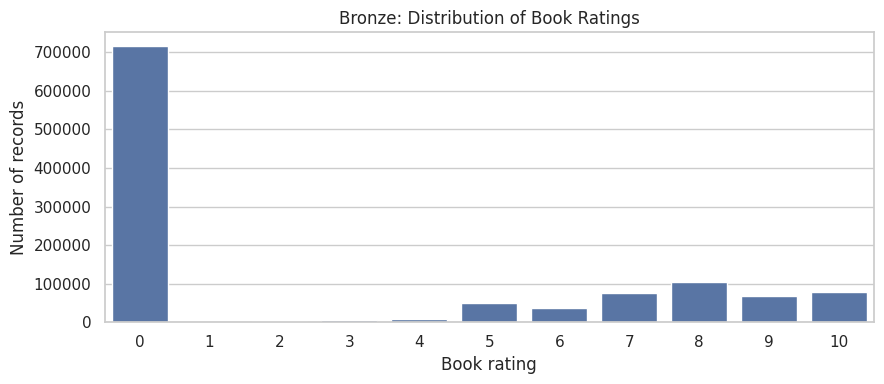

In [14]:
# Rating distribution, including the count of zero ratings.
rating_counts = ratings_bronze["Book-Rating"].value_counts(dropna=False).sort_index()
display(rating_counts.to_frame("count"))
zero_rating_count = int((ratings_bronze["Book-Rating"] == 0).sum())
print("Number of zero ratings:", f"{zero_rating_count:,}")

plt.figure(figsize=(9, 4))
sns.countplot(
    data=ratings_bronze,
    x="Book-Rating",
    order=sorted(ratings_bronze["Book-Rating"].dropna().unique())
)
plt.title("Bronze: Distribution of Book Ratings")
plt.xlabel("Book rating")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64
Missing/non-numeric ages: 110762
Ages below 5: 882
Ages above 100: 366


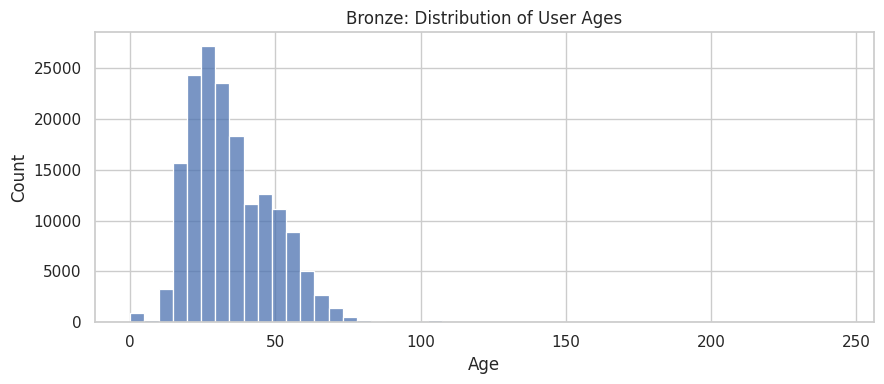

In [15]:
# User age distribution and impossible values.
age_numeric = pd.to_numeric(users_bronze["Age"], errors="coerce")
print(age_numeric.describe())
print("Missing/non-numeric ages:", int(age_numeric.isna().sum()))
print("Ages below 5:", int((age_numeric < 5).sum()))
print("Ages above 100:", int((age_numeric > 100).sum()))

plt.figure(figsize=(9, 4))
sns.histplot(age_numeric.dropna(), bins=50)
plt.title("Bronze: Distribution of User Ages")
plt.xlabel("Age")
plt.tight_layout()
plt.show()

count    270491.000000
mean       1959.704914
std         258.207234
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64
Missing/non-numeric publication years: 0
Publication year equal to zero: 4611
Future publication years: 11


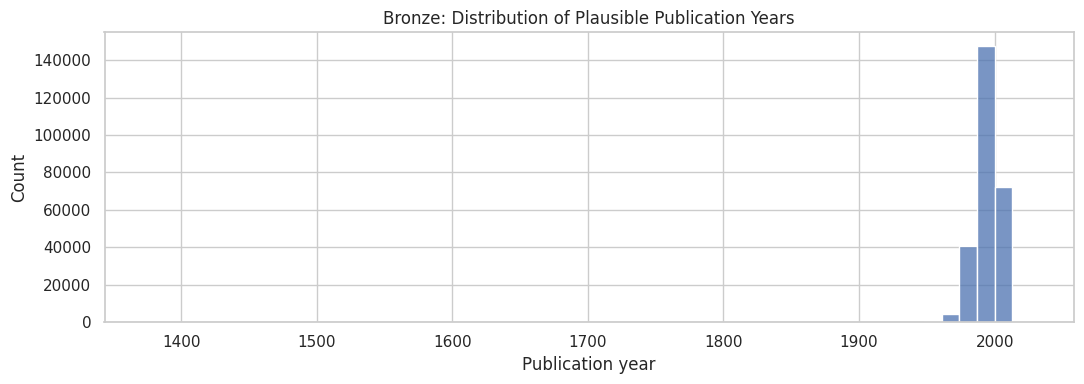

In [16]:
# Publication year distribution and suspicious values.
year_numeric = pd.to_numeric(
    books_bronze["Year-Of-Publication"], errors="coerce"
)
current_year = datetime.now().year

print(year_numeric.describe())
print("Missing/non-numeric publication years:", int(year_numeric.isna().sum()))
print("Publication year equal to zero:", int((year_numeric == 0).sum()))
print("Future publication years:", int((year_numeric > current_year).sum()))

valid_years = year_numeric[year_numeric.between(1000, current_year)]
plt.figure(figsize=(11, 4))
sns.histplot(valid_years, bins=50)
plt.title("Bronze: Distribution of Plausible Publication Years")
plt.xlabel("Publication year")
plt.tight_layout()
plt.show()

Ratings per user:


,ratings_per_user
count,105283.000000
mean,10.920851
std,90.562825
min,1.000000
25%,1.000000
50%,1.000000
75%,4.000000
max,13602.000000


Ratings per book:


,ratings_per_book
count,340556.000000
mean,3.376185
std,12.436252
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,2502.000000


Users with fewer than 10 rating rows: 92186
Books with fewer than 10 rating rows: 322237


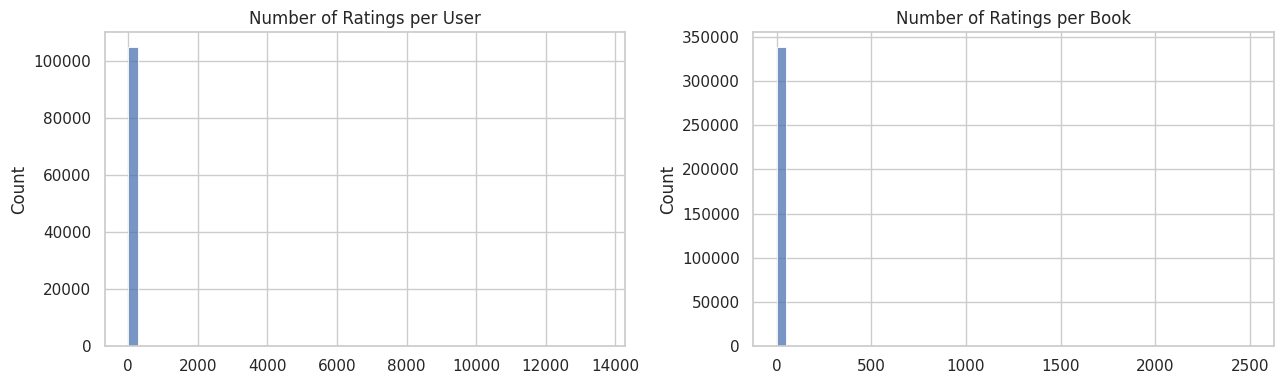

In [17]:
# Ratings per user and per book.
ratings_per_user_bronze = ratings_bronze.groupby("User-ID").size()
ratings_per_book_bronze = ratings_bronze.groupby("ISBN").size()

print("Ratings per user:")
display(ratings_per_user_bronze.describe().to_frame("ratings_per_user"))
print("Ratings per book:")
display(ratings_per_book_bronze.describe().to_frame("ratings_per_book"))

print("Users with fewer than 10 rating rows:",
      int((ratings_per_user_bronze < 10).sum()))
print("Books with fewer than 10 rating rows:",
      int((ratings_per_book_bronze < 10).sum()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(ratings_per_user_bronze, bins=50, ax=axes[0])
axes[0].set_title("Number of Ratings per User")
sns.histplot(ratings_per_book_bronze, bins=50, ax=axes[1])
axes[1].set_title("Number of Ratings per Book")
plt.tight_layout()
plt.show()

In [18]:
# Matrix sparsity. Count distinct observed user-book pairs, not raw rows,
# so duplicate interaction rows do not inflate the density.
n_users_bronze = ratings_bronze["User-ID"].nunique()
n_books_bronze = ratings_bronze["ISBN"].nunique()
observed_pairs = ratings_bronze[["User-ID", "ISBN"]].drop_duplicates().shape[0]
possible_pairs = n_users_bronze * n_books_bronze

sparsity_pct = (
    100 * (1 - observed_pairs / possible_pairs)
    if possible_pairs else float("nan")
)

print(f"Unique users in ratings: {n_users_bronze:,}")
print(f"Unique books in ratings: {n_books_bronze:,}")
print(f"Distinct observed user-book pairs: {observed_pairs:,}")
print(f"Possible user-book pairs: {possible_pairs:,}")
print(f"Matrix sparsity: {sparsity_pct:.4f}%")

Unique users in ratings: 105,283
Unique books in ratings: 340,556
Distinct observed user-book pairs: 1,149,780
Possible user-book pairs: 35,854,757,348
Matrix sparsity: 99.9968%


### EDA observations and planned Silver actions

After running the EDA cells, record concise, data-backed observations here. Do not leave generic claims in place of the actual values.

- **Shapes, types and missing values:** Note the displayed table dimensions and the columns with the most missing values. In Silver, handle missing ages and invalid numeric fields, while retaining optional book metadata when it is not required by the model.
- **Rating distribution:** Note the number of zero ratings shown above. In Silver, retain only explicit ratings from 1 through 10.
- **Age distribution:** Note the number of ages below 5 and above 100. In Silver, set those values to null and impute null ages with the median.
- **Publication years:** Note zero, non-numeric and future years. In Silver, set zero and future years to null; non-numeric years are also coerced to null.
- **Ratings per user/book:** Use the counts and histograms to assess the long tail. In Silver, apply a minimum of 10 explicit ratings to each retained user and book.
- **Sparsity:** Record the calculated percentage. In Gold, use a SciPy sparse matrix rather than a dense matrix.

## 6. Silver layer — clean and validate

The Silver layer is built from Bronze, not from the raw CSV variables. Exact duplicate rows are removed. Conflicting repeated user-book interactions are consolidated to one interaction using the rounded mean rating so that each matrix cell has one unambiguous value.

In [19]:
users = pd.read_parquet("bronze/users.parquet").copy()
books = pd.read_parquet("bronze/books.parquet").copy()
ratings = pd.read_parquet("bronze/ratings.parquet").copy()

# Remove exact duplicate rows first.
users = users.drop_duplicates()
books = books.drop_duplicates()
ratings = ratings.drop_duplicates()

# Enforce one record per entity identifier.
users = users.drop_duplicates(subset=["User-ID"], keep="first")
books = books.drop_duplicates(subset=["ISBN"], keep="first")

# Normalize key types.
books["ISBN"] = books["ISBN"].astype("string").str.strip()
ratings["ISBN"] = ratings["ISBN"].astype("string").str.strip()

In [20]:
# Clean ratings: explicit ratings only, within the assignment's 1–10 range.
ratings["Book-Rating"] = pd.to_numeric(
    ratings["Book-Rating"], errors="coerce"
)
ratings = ratings[
    ratings["Book-Rating"].between(1, 10)
].copy()
ratings["Book-Rating"] = ratings["Book-Rating"].astype("int16")

# Resolve any remaining duplicate user-book pairs (potentially conflicting scores).
# The rounded mean is deterministic and leaves one value per matrix coordinate.
ratings = (
    ratings.groupby(["User-ID", "ISBN"], as_index=False)["Book-Rating"]
    .mean()
)
ratings["Book-Rating"] = ratings["Book-Rating"].round().astype("int16")

print("Ratings after explicit-rating and interaction deduplication:", ratings.shape)
print("Rating range:", ratings["Book-Rating"].min(), "to", ratings["Book-Rating"].max())

Ratings after explicit-rating and interaction deduplication: (433671, 3)
Rating range: 1 to 10


In [21]:
# Clean user ages: below 5 or above 100 becomes null, then median imputation.
users["Age"] = pd.to_numeric(users["Age"], errors="coerce")
users.loc[(users["Age"] < 5) | (users["Age"] > 100), "Age"] = np.nan

median_age = users["Age"].median()
if pd.isna(median_age):
    raise ValueError("No valid age values remain; median imputation is not possible.")

users["Age"] = users["Age"].fillna(median_age).round().astype("int64")
print("Median age used for imputation:", median_age)
print(users["Age"].describe())

Median age used for imputation: 32.0
count    278858.000000
mean         33.643385
std          10.630979
min           5.000000
25%          29.000000
50%          32.000000
75%          35.000000
max         100.000000
Name: Age, dtype: float64


In [22]:
# Split Location into city, state and country.
# Missing components remain empty strings; no geographic inference is made.
location = users["Location"].fillna("").astype(str).str.strip().str.lower()
location_parts = location.str.split(",", n=2, expand=True)
location_parts = location_parts.reindex(columns=[0, 1, 2])

users["city"] = location_parts[0].fillna("").str.strip()
users["state"] = location_parts[1].fillna("").str.strip()
users["country"] = location_parts[2].fillna("").str.strip()
users = users.drop(columns=["Location"])

display(users[["city", "state", "country"]].head())

,city,state,country
0,nyc,new york,usa
1,stockton,california,usa
2,moscow,yukon territory,russia
3,porto,v.n.gaia,portugal
4,farnborough,hants,united kingdom


In [23]:
# Publication years: coerce non-numeric values, then null zero and future years.
books["Year-Of-Publication"] = pd.to_numeric(
    books["Year-Of-Publication"], errors="coerce"
)
current_year = datetime.now().year
invalid_year = (
    (books["Year-Of-Publication"] == 0) |
    (books["Year-Of-Publication"] > current_year)
)
books.loc[invalid_year, "Year-Of-Publication"] = np.nan

# Clean text fields: trim whitespace, collapse repeated spaces and standardize case.
for column in ["Book-Title", "Book-Author", "Publisher"]:
    if column in books.columns:
        books[column] = (
            books[column].fillna("").astype(str)
            .str.strip()
            .str.replace(r"\s+", " ", regex=True)
            .str.title()
        )
        books[column] = books[column].replace("", np.nan)

# Image URLs are not needed for this recommender.
books = books.drop(
    columns=["Image-URL-S", "Image-URL-M", "Image-URL-L"],
    errors="ignore"
)

print("Book metadata cleaned.")
display(books.head())

Book metadata cleaned.


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,ingestion_timestamp
0,0195153448,Classical Mythology,Mark P. O. Morford,2002.0,Oxford University Press,2026-11-26 16:38:03.427695+00:00
1,0002005018,Clara Callan,Richard Bruce Wright,2001.0,Harperflamingo Canada,2026-11-26 16:38:03.427695+00:00
2,0060973129,Decision In Normandy,Carlo D'Este,1991.0,Harperperennial,2026-11-26 16:38:03.427695+00:00
3,0374157065,Flu: The Story Of The Great Influenza Pandemic Of 1918 And The Search For The Virus That Caused It,Gina Bari Kolata,1999.0,Farrar Straus Giroux,2026-11-26 16:38:03.427695+00:00
4,0393045218,The Mummies Of Urumchi,E. J. W. Barber,1999.0,W. W. Norton &Amp; Company,2026-11-26 16:38:03.427695+00:00


In [24]:
# Keep ratings only when both referenced entities exist.
ratings = ratings[
    ratings["User-ID"].isin(users["User-ID"]) &
    ratings["ISBN"].isin(books["ISBN"])
].copy()

# Iteratively enforce at least MIN_RATINGS explicit interactions for every
# retained user and every retained book. Iteration is necessary because
# filtering one side can reduce counts on the other side.
while True:
    previous_count = len(ratings)

    user_counts = ratings.groupby("User-ID").size()
    eligible_users = user_counts[user_counts >= MIN_RATINGS].index
    ratings = ratings[ratings["User-ID"].isin(eligible_users)]

    book_counts = ratings.groupby("ISBN").size()
    eligible_books = book_counts[book_counts >= MIN_RATINGS].index
    ratings = ratings[ratings["ISBN"].isin(eligible_books)]

    if len(ratings) == previous_count:
        break

# Keep only entities that still participate in the filtered interactions.
users = users[users["User-ID"].isin(ratings["User-ID"].unique())].copy()
books = books[books["ISBN"].isin(ratings["ISBN"].unique())].copy()

if ratings.empty:
    raise ValueError(
        "No interactions remain after filtering. Revisit MIN_RATINGS or inspect the input data."
    )

print("Chosen threshold:", MIN_RATINGS, "explicit ratings per user and per book")
print("Silver users:", users.shape)
print("Silver books:", books.shape)
print("Silver ratings:", ratings.shape)

Chosen threshold: 10 explicit ratings per user and per book
Silver users: (1813, 6)
Silver books: (2022, 6)
Silver ratings: (41238, 3)


In [25]:
# Silver validation.
assert users["User-ID"].is_unique
assert books["ISBN"].is_unique
assert not ratings.duplicated(["User-ID", "ISBN"]).any()
assert ratings["Book-Rating"].between(1, 10).all()
assert ratings["User-ID"].isin(users["User-ID"]).all()
assert ratings["ISBN"].isin(books["ISBN"]).all()
assert ratings.groupby("User-ID").size().min() >= MIN_RATINGS
assert ratings.groupby("ISBN").size().min() >= MIN_RATINGS

print("All Silver validation checks passed.")
print("\nRemaining missing values — users:")
display(users.isna().sum().to_frame("missing"))
print("\nRemaining missing values — books:")
display(books.isna().sum().to_frame("missing"))
print("\nRemaining missing values — ratings:")
display(ratings.isna().sum().to_frame("missing"))

All Silver validation checks passed.

Remaining missing values — users:


,missing
User-ID,0
Age,0
ingestion_timestamp,0
city,0
state,0
country,0



Remaining missing values — books:


,missing
ISBN,0
Book-Title,0
Book-Author,0
Year-Of-Publication,4
Publisher,0
ingestion_timestamp,0



Remaining missing values — ratings:


,missing
User-ID,0
ISBN,0
Book-Rating,0


In [26]:
users.to_parquet("silver/users_silver.parquet", index=False)
books.to_parquet("silver/books_silver.parquet", index=False)
ratings.to_parquet("silver/ratings_silver.parquet", index=False)

print("Silver Parquet files saved.")

Silver Parquet files saved.


### Why use a threshold of 10?

The Bronze EDA shows the long-tail pattern in user and book activity: many entities have only a small number of interactions. A minimum of 10 explicit ratings is used as a practical support threshold so item similarities are based on a less sparse subset. It is a design choice for this assignment, not a universal optimum. The final retained counts are printed above.

## 7. Gold layer — model-ready data

Gold contains the sparse user-book matrix, mappings needed to interpret its row/column indices, a readable book lookup table, and user/book aggregates.

In [27]:
users = pd.read_parquet("silver/users_silver.parquet")
books = pd.read_parquet("silver/books_silver.parquet")
ratings = pd.read_parquet("silver/ratings_silver.parquet")

# Stable index mappings. Each row of rating_matrix is a user;
# each column is a book.
user_ids = np.sort(ratings["User-ID"].unique())
book_ids = np.sort(ratings["ISBN"].astype(str).unique())

user_to_index = {user_id: idx for idx, user_id in enumerate(user_ids)}
book_to_index = {isbn: idx for idx, isbn in enumerate(book_ids)}

row_indices = ratings["User-ID"].map(user_to_index).to_numpy()
col_indices = ratings["ISBN"].astype(str).map(book_to_index).to_numpy()
rating_values = ratings["Book-Rating"].astype(np.float32).to_numpy()

rating_matrix = csr_matrix(
    (rating_values, (row_indices, col_indices)),
    shape=(len(user_ids), len(book_ids)),
    dtype=np.float32
)

print("User-book sparse matrix shape:", rating_matrix.shape)
print("Stored non-zero ratings:", rating_matrix.nnz)
print("Dense cell count (not allocated):", rating_matrix.shape[0] * rating_matrix.shape[1])

User-book sparse matrix shape: (1813, 2022)
Stored non-zero ratings: 41238
Dense cell count (not allocated): 3665886


In [28]:
# Save sparse matrix and explicit index lookup tables.
save_npz("gold/user_book_matrix.npz", rating_matrix)

user_lookup = pd.DataFrame({
    "user_id": user_ids,
    "user_index": np.arange(len(user_ids), dtype=np.int64)
})
book_index = pd.DataFrame({
    "isbn": book_ids,
    "book_index": np.arange(len(book_ids), dtype=np.int64)
})

user_lookup.to_parquet("gold/user_lookup.parquet", index=False)
book_index.to_parquet("gold/book_index.parquet", index=False)

book_lookup = books[["ISBN", "Book-Title", "Book-Author"]].copy()
book_lookup.columns = ["isbn", "title", "author"]
book_lookup["isbn"] = book_lookup["isbn"].astype(str)
book_lookup.to_parquet("gold/book_lookup.parquet", index=False)

display(book_lookup.head())

,isbn,title,author
0,0440234743,The Testament,John Grisham
1,0452264464,Beloved (Plume Contemporary Fiction),Toni Morrison
2,0971880107,Wild Animus,Rich Shapero
3,0345402871,Airframe,Michael Crichton
4,0345417623,Timeline,Michael Crichton


In [29]:
# User-level and book-level aggregates.
user_aggregates = (
    ratings.groupby("User-ID")["Book-Rating"]
    .agg(average_rating="mean", number_of_ratings="count")
    .reset_index()
)
book_aggregates = (
    ratings.groupby("ISBN")["Book-Rating"]
    .agg(average_rating="mean", number_of_ratings="count")
    .reset_index()
)

user_aggregates.to_parquet("gold/user_aggregates.parquet", index=False)
book_aggregates.to_parquet("gold/book_aggregates.parquet", index=False)

print("User aggregates:")
display(user_aggregates.head())
print("Book aggregates:")
display(book_aggregates.head())

User aggregates:


,User-ID,average_rating,number_of_ratings
0,243,7.769231,13
1,254,8.450000,20
2,638,9.454545,22
3,805,8.400000,10
4,882,8.235294,17


Book aggregates:


,ISBN,average_rating,number_of_ratings
0,0020199600,8.090909,11
1,0020442203,8.833333,12
2,002542730X,7.481481,27
3,0028604199,7.900000,10
4,0060002050,7.545455,11


## 8. Item-based collaborative filtering

The recommender treats each book as a vector of ratings from users. The matrix is transposed so books are rows and users are columns. Cosine distance is used by scikit-learn's `NearestNeighbors`; similarity is calculated as `1 - distance`.

In [30]:
# Load the Gold matrix from disk and transpose it:
# rows = books, columns = users.
rating_matrix = load_npz("gold/user_book_matrix.npz")
item_user_matrix = rating_matrix.T.tocsr()

user_lookup = pd.read_parquet("gold/user_lookup.parquet")
book_index = pd.read_parquet("gold/book_index.parquet")
book_lookup = pd.read_parquet("gold/book_lookup.parquet")
book_aggregates = pd.read_parquet("gold/book_aggregates.parquet")

user_to_index = dict(zip(user_lookup["user_id"], user_lookup["user_index"]))
book_to_index = dict(zip(book_index["isbn"], book_index["book_index"]))
index_to_book = dict(zip(book_index["book_index"], book_index["isbn"]))

isbn_to_title = dict(zip(book_lookup["isbn"], book_lookup["title"]))
isbn_to_author = dict(zip(book_lookup["isbn"], book_lookup["author"]))

# Choose one representative ISBN for each title: the ISBN with the most ratings.
title_counts = book_aggregates.set_index("ISBN")["number_of_ratings"].to_dict()
book_lookup["title_key"] = book_lookup["title"].fillna("").str.strip().str.casefold()

title_to_isbn = {}
for title_key, group in book_lookup.groupby("title_key"):
    if title_key:
        candidates = group["isbn"].tolist()
        title_to_isbn[title_key] = max(
            candidates,
            key=lambda isbn: title_counts.get(isbn, 0)
        )

n_books = item_user_matrix.shape[0]
if n_books < 2:
    raise ValueError("At least two books are required to build a similarity model.")

neighbor_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=min(11, n_books),
    n_jobs=-1
)
neighbor_model.fit(item_user_matrix)

print("Item-based cosine-neighbour model fitted.")
print("Books:", n_books, "| Users:", item_user_matrix.shape[1])

Item-based cosine-neighbour model fitted.
Books: 2022 | Users: 1813


In [31]:
def similar_books(book_title, n=10):
    """Return up to n books most similar to the supplied title."""
    if n <= 0:
        return pd.DataFrame(columns=["Title", "Author", "Similarity"])

    title_key = str(book_title).strip().casefold()
    if title_key not in title_to_isbn:
        print("Book title not found in the filtered Gold data.")
        return pd.DataFrame(columns=["Title", "Author", "Similarity"])

    isbn = title_to_isbn[title_key]
    book_idx = int(book_to_index[isbn])

    k = min(n + 1, n_books)
    distances, indices = neighbor_model.kneighbors(
        item_user_matrix[book_idx],
        n_neighbors=k
    )

    results = []
    for distance, neighbor_idx in zip(distances[0], indices[0]):
        neighbor_idx = int(neighbor_idx)
        if neighbor_idx == book_idx:
            continue

        neighbor_isbn = index_to_book[neighbor_idx]
        results.append({
            "Title": isbn_to_title.get(neighbor_isbn, "Unknown"),
            "Author": isbn_to_author.get(neighbor_isbn, "Unknown"),
            "Similarity": float(1.0 - distance)
        })
        if len(results) >= n:
            break

    return pd.DataFrame(results)

### Try the similar-books function

The following example uses a real title from the filtered Gold lookup table, so it does not assume that a particular popular title survived the filtering threshold.

In [32]:
example_title = book_lookup["title"].dropna().iloc[0]
print("Example input title:", example_title)
display(similar_books(example_title, n=10))

Example input title: The Testament


,Title,Author,Similarity
0,Monster : A Novel (Alex Delaware Novels (Paperback)),Jonathan Kellerman,0.252806
1,The Runaway Jury,John Grisham,0.237765
2,The Bone Collector (Lincoln Rhyme Novels (Paperback)),Jeff Deaver,0.237577
3,Call Of The Wild,Jack London,0.235941
4,The Simple Truth,David Baldacci,0.235625
5,The Street Lawyer,John Grisham,0.219808
6,Atlantis Found,Clive Cussler,0.199432
7,Outbreak,Robin Cook,0.198693
8,From Potter'S Field,Patricia Daniels Cornwell,0.196162
9,Writ Of Execution,Perri O'Shaughnessy,0.190140


## 9. Personalized recommendations

For a user, select books rated at least 7. For each such book, retrieve its nearest neighbours. A candidate receives a weighted score based on the source book's user rating and the cosine similarity. Candidates already rated by the user are excluded.

The returned score is a similarity-weighted preference score, not a calibrated prediction of a 1–10 rating.

In [33]:
def recommend(user_id, n=10):
    """Recommend up to n unseen books using a similarity-weighted score."""
    columns = ["ISBN", "Title", "Author", "Score"]

    if n <= 0:
        return pd.DataFrame(columns=columns)

    if user_id not in user_to_index:
        print(f"User {user_id} is not present in the filtered Gold data.")
        return pd.DataFrame(columns=columns)

    user_idx = int(user_to_index[user_id])
    user_row = rating_matrix.getrow(user_idx)

    already_rated = set(int(idx) for idx in user_row.indices)
    liked_books = [
        (int(book_idx), float(rating))
        for book_idx, rating in zip(user_row.indices, user_row.data)
        if rating >= HIGH_RATING
    ]

    if not liked_books:
        print(f"User {user_id} has no ratings >= {HIGH_RATING}.")
        return pd.DataFrame(columns=columns)

    weighted_similarity_sum = {}
    similarity_sum = {}

    for source_book_idx, user_rating in liked_books:
        k = min(11, n_books)
        distances, indices = neighbor_model.kneighbors(
            item_user_matrix[source_book_idx],
            n_neighbors=k
        )

        for distance, candidate_idx in zip(distances[0], indices[0]):
            candidate_idx = int(candidate_idx)
            similarity = float(1.0 - distance)

            # Exclude the source book, all books already rated by the user,
            # and non-positive similarities.
            if candidate_idx in already_rated or similarity <= 0:
                continue

            weighted_similarity_sum[candidate_idx] = (
                weighted_similarity_sum.get(candidate_idx, 0.0)
                + user_rating * similarity
            )
            similarity_sum[candidate_idx] = (
                similarity_sum.get(candidate_idx, 0.0)
                + similarity
            )

    scored_candidates = []
    for candidate_idx, weighted_sum in weighted_similarity_sum.items():
        denom = similarity_sum[candidate_idx]
        if denom > 0:
            scored_candidates.append(
                (candidate_idx, weighted_sum / denom)
            )

    scored_candidates.sort(key=lambda item: (-item[1], item[0]))

    results = []
    for candidate_idx, score in scored_candidates[:n]:
        isbn = index_to_book[candidate_idx]
        results.append({
            "ISBN": isbn,
            "Title": isbn_to_title.get(isbn, "Unknown"),
            "Author": isbn_to_author.get(isbn, "Unknown"),
            "Score": round(float(score), 4)
        })

    return pd.DataFrame(results, columns=columns)

## 10. Demo and sanity checks — at least three users

Select users with at least 15 interactions and at least one high rating. We try users in descending interaction count and retain the first three who receive at least one recommendation. This avoids hardcoded IDs and makes the demo data-driven.

In [34]:
rating_counts_by_user = ratings.groupby("User-ID").size()
high_rating_counts = (
    ratings[ratings["Book-Rating"] >= HIGH_RATING]
    .groupby("User-ID").size()
)

demo_candidates = (
    rating_counts_by_user[rating_counts_by_user >= 15]
    .index.intersection(high_rating_counts.index)
)
demo_candidates = sorted(
    demo_candidates,
    key=lambda uid: (-int(rating_counts_by_user.loc[uid]), uid)
)

demo_users = []
for candidate_user in demo_candidates:
    candidate_recommendations = recommend(candidate_user, n=10)
    if not candidate_recommendations.empty:
        demo_users.append(candidate_user)
    if len(demo_users) == 3:
        break

if len(demo_users) < 3:
    raise RuntimeError(
        "Could not find three users with non-empty recommendations. "
        "Inspect the filtered data and consider documenting a lower demo-user "
        "activity cutoff; do not silently change the Silver threshold."
    )

print("Selected demo users:", demo_users)

Selected demo users: [11676, 16795, 95359]


In [35]:
def show_user_demo(user_id):
    print("\n" + "=" * 85)
    print("USER ID:", user_id)
    print("=" * 85)

    user_history = ratings[ratings["User-ID"] == user_id].copy()
    liked = user_history[user_history["Book-Rating"] >= HIGH_RATING].copy()
    liked = liked.sort_values(
        ["Book-Rating", "ISBN"], ascending=[False, True]
    ).head(10)

    liked_display = liked.merge(
        book_lookup,
        left_on="ISBN",
        right_on="isbn",
        how="left"
    )
    print(f"Books rated highly (rating >= {HIGH_RATING}):")
    display(
        liked_display[["title", "author", "Book-Rating"]]
        .rename(columns={"title": "Book", "author": "Author", "Book-Rating": "User Rating"})
    )

    print("Recommended books:")
    recs = recommend(user_id, n=10)
    display(recs[["Title", "Author", "Score"]])
    return recs

demo_results = {}
for uid in demo_users:
    demo_results[uid] = show_user_demo(uid)


USER ID: 11676
Books rated highly (rating >= 7):


,Book,Author,User Rating
0,The Poisonwood Bible,Barbara Kingsolver,10
1,Daughter Of Fortune : A Novel (Oprah'S Book Club (Hardcover)),Isabel Allende,10
2,Prodigal Summer,Barbara Kingsolver,10
3,I Know This Much Is True (Oprah'S Book Club),Wally Lamb,10
4,The Poisonwood Bible,Barbara Kingsolver,10
5,To Kill A Mockingbird,Harper Lee,10
6,Fast Food Nation: The Dark Side Of The All-American Meal,Eric Schlosser,10
7,"The Professor And The Madman: A Tale Of Murder, Insanity, And The Making Of The Oxford English D...",Simon Winchester,10
8,Courting Trouble,Lisa Scottoline,10
9,The Alchemist: A Fable About Following Your Dream,Paulo Coelho,10


Recommended books:


,Title,Author,Score
0,Great Gatsby (Reissue),F. Scott Fitzgerald,10.0
1,The Giving Tree,Shel Silverstein,10.0
2,The Poisonwood Bible: A Novel,Barbara Kingsolver,10.0
3,Daughter Of Fortune,Isabel Allende,10.0
4,Microserfs,Douglas Coupland,10.0
5,Small Gods (Discworld Novels (Paperback)),Terry Pratchett,10.0
6,"Catherine, Called Birdy (Trophy Newbery)",Karen Cushman,10.0
7,"The Wide Window (A Series Of Unfortunate Events, Book 3)",Lemony Snicket,10.0
8,"The Miserable Mill (A Series Of Unfortunate Events, Book 4)",Lemony Snicket,10.0
9,"The Hostile Hospital (A Series Of Unfortunate Events, Book 8)",Lemony Snicket,10.0



USER ID: 16795
Books rated highly (rating >= 7):


,Book,Author,User Rating
0,The Liar'S Club: A Memoir,Mary Karr,10
1,The Secret Life Of Bees,Sue Monk Kidd,10
2,Life Of Pi,Yann Martel,10
3,The Samurai'S Garden : A Novel,Gail Tsukiyama,10
4,The Dogs Of Babel (Today Show Book Club #12),Carolyn Parkhurst,10
5,The Lovely Bones: A Novel,Alice Sebold,10
6,How Reading Changed My Life (Library Of Contemporary Thought),Anna Quindlen,10
7,The Dive From Clausen'S Pier (Alex Awards),Ann Packer,10
8,The Da Vinci Code,Dan Brown,10
9,Skipping Christmas,John Grisham,10


... (2 outputs left out)


USER ID: 95359
Books rated highly (rating >= 7):


,Book,Author,User Rating
0,Stupid White Men ...And Other Sorry Excuses For The State Of The Nation!,Michael Moore,10
1,The Westing Game (Now In Speak!),Ellen Raskin,10
2,Year Of Wonders,Geraldine Brooks,10
3,"Word Freak: Heartbreak, Triumph, Genius, And Obsession In The World Of Competitive Scrabble Players",Stefan Fatsis,10
4,The Hours : A Novel,Michael Cunningham,10
5,The Hours: A Novel,Michael Cunningham,10
6,The Pilot'S Wife : A Novel,Anita Shreve,10
7,A Prayer For Owen Meany,John Irving,10
8,The Hitchhiker'S Guide To The Galaxy,Douglas Adams,10
9,House Of Leaves,Mark Z. Danielewski,10


Recommended books:


,Title,Author,Score
0,Stuart Little,E. B. White,10.0
1,"The Austere Academy (A Series Of Unfortunate Events, Book 5)",Lemony Snicket,10.0
2,"Princess In The Spotlight (The Princess Diaries, Vol. 2)",Meg Cabot,10.0
3,Memoirs Of A Geisha Uk,Arthur Golden,10.0
4,Obasan,Joy Kogawa,10.0
5,On The Road (Penguin 20Th Century Classics),Jack Kerouac,10.0
6,Death Of A Salesman,Arthur Miller,10.0
7,Where Or When : A Novel,Anita Shreve,10.0
8,Not Without My Daughter,Betty Mahmoody,10.0
9,Crazy For You,Jennifer Crusie,10.0


In [36]:
# Sanity checks: recommendations are non-empty, unseen by ISBN,
# and have finite scores.
for uid, recs in demo_results.items():
    user_idx = int(user_to_index[uid])
    seen_indices = set(int(x) for x in rating_matrix.getrow(user_idx).indices)
    recommended_isbns = recs["ISBN"].astype(str).tolist()
    recommended_indices = {int(book_to_index[isbn]) for isbn in recommended_isbns}

    assert not recs.empty
    assert seen_indices.isdisjoint(recommended_indices)
    assert recs["Score"].notna().all()
    assert np.isfinite(recs["Score"]).all()

print("Sanity checks passed: all three users received recommendations,")
print("no recommended ISBN was already rated, and all scores are finite.")


Sanity checks passed: all three users received recommendations,
no recommended ISBN was already rated, and all scores are finite.


## 11. Save a portable output bundle

The notebook itself is the main deliverable. This cell also packages the generated Bronze, Silver and Gold folders so that the Parquet files and sparse matrix can be downloaded after the notebook has run.

In [37]:
output_zip = "book_recommender_data_layers.zip"

with zipfile.ZipFile(output_zip, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for folder in ["bronze", "silver", "gold"]:
        for root, _, files in os.walk(folder):
            for filename in files:
                full_path = os.path.join(root, filename)
                zf.write(full_path, arcname=full_path)

print("Created:", output_zip)

try:
    from google.colab import files
    files.download(output_zip)
except ImportError:
    print("Not running in Google Colab. The ZIP is saved in the current directory.")

Created: book_recommender_data_layers.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
import os
import zipfile

for folder in ["bronze", "silver", "gold"]:

    zip_name = folder + ".zip"

    with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zf:

        for root, dirs, files_list in os.walk(folder):
            for file in files_list:
                path = os.path.join(root, file)
                zf.write(path, arcname=path)

    print(
        zip_name,
        round(os.path.getsize(zip_name) / (1024 * 1024), 2),
        "MB"
    )

bronze.zip 26.74 MB
silver.zip 0.18 MB
gold.zip 0.21 MB


In [39]:
import os

for file in os.listdir("bronze"):
    path = os.path.join("bronze", file)
    print(file, round(os.path.getsize(path) / (1024 * 1024), 2), "MB")

books.parquet 20.57 MB
users.parquet 4.15 MB
ratings.parquet 9.36 MB


In [40]:
import zipfile
import os

# First archive
with zipfile.ZipFile("bronze_part1.zip", "w", zipfile.ZIP_DEFLATED) as z:
    z.write("bronze/books.parquet", "bronze/books.parquet")

# Second archive
with zipfile.ZipFile("bronze_part2.zip", "w", zipfile.ZIP_DEFLATED) as z:
    z.write("bronze/users.parquet", "bronze/users.parquet")
    z.write("bronze/ratings.parquet", "bronze/ratings.parquet")

# Check sizes
for f in ["bronze_part1.zip", "bronze_part2.zip"]:
    print(f, round(os.path.getsize(f)/(1024*1024), 2), "MB")

bronze_part1.zip 16.5 MB
bronze_part2.zip 10.24 MB


In [41]:
from google.colab import files

for f in [
    "bronze_part1.zip",
    "bronze_part2.zip",
    "silver.zip",
    "gold.zip"
]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Conclusion

This assignment implemented an end-to-end Medallion data lake for the Book-Crossing dataset. The Bronze layer preserved the parsed source tables with ingestion timestamps. EDA was used to inspect data quality, rating distributions, age and publication-year anomalies, interaction counts and matrix sparsity. The Silver layer cleaned and validated the data, retained explicit ratings, handled missing and invalid values, split user locations, and applied a minimum interaction threshold. The Gold layer stored a sparse user-book rating matrix, lookup tables and user/book aggregates. Finally, an item-based collaborative filtering model used cosine similarity to find similar books and generate personalized recommendations from books rated highly by a user.

The demo section runs the recommender for three distinct users and displays their highly rated books alongside recommendations. The recommendation score is a similarity-weighted preference score rather than a calibrated rating prediction.